# Prediksi Kurs Rupiah terhadap Dolar AS Menggunakan Machine Learning

Berdasarkan riwayat kurs rupiah dan mata uang negara berkembang Asia.

Membandingkan **XGBoost** dan **SVR kernel RBF** dalam memprediksi IDR/USD pada observasi
berikutnya dari **lima lag terakhir**, pada beberapa konfigurasi variabel prediktor.

- **Sumber data:** CSV riwayat harga Investing.com di folder proyek. Tidak ada pengunduhan dari internet.
- **Variabel:** IDR/USD sebagai target; MYR/USD, THB/USD, INR/USD sebagai prediktor potensial.
- **Konfigurasi:** IDR saja, IDR ditambah satu mata uang lain secara bergantian, dan seluruh mata uang bersamaan.
- **Evaluasi:** MAE, RMSE, MAPE, R2, dan Theil's U terhadap random walk; pembagian 80:20 kronologis.
- **Pengujian lanjutan:** Diebold-Mariano (paket `dieboldmariano`) dengan koreksi Holm, uji ADF, target return, analisis
  ekstrapolasi, dan korelasi antarhari.
- **Keluaran:** CSV dan PNG di folder `hasil/`.


## 1. Pustaka dan pengaturan


In [ ]:
import glob
import json
import os
import warnings
from collections import namedtuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dieboldmariano import dm_test
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import mean_absolute_percentage_error as mape
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error as rmse
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
os.makedirs("hasil", exist_ok=True)

TARGET = "IDR"
PREDIKTOR = ["MYR", "THB", "INR"]
CUR = [TARGET] + PREDIKTOR

# Investing.com menampilkan IDR per 1.000 rupiah dan INR per 100 rupee. Faktor ini mengembalikan
# semua seri ke satuan "mata uang lokal per 1 USD", jadi IDR menjadi rupiah per USD.
FAKTOR = {"IDR": 1000, "INR": 100, "MYR": 1, "THB": 1}
# Rentang wajar sebagai pemeriksaan: kalau satuan atau format berkas berubah, assert gagal.
WAJAR = {"IDR": (8e3, 3e4), "MYR": (2, 7), "THB": (20, 50), "INR": (40, 120)}

LAGS = 5
FRAC = 0.8  # 80% latih, 20% uji, kronologis
START, END = "2015-01-01", "2026-09-30"

SCEN = {"K1 (IDR)": [TARGET]}
for i, c in enumerate(PREDIKTOR, start=2):
    SCEN[f"K{i} (IDR+{c})"] = [TARGET, c]
SCEN[f"K{len(PREDIKTOR) + 2} (Semua)"] = CUR

SVR_GRID = {
    "C": [1, 10, 100, 1000],
    "gamma": [0.001, 0.01, 0.1, 1],
    "epsilon": [0.001, 0.01, 0.1],
}
SVR_GRID_RETURN = {"C": [0.1, 1], "gamma": [0.001, 0.01], "epsilon": [0.01, 0.1]}
XGB_GRID = {
    "n_estimators": [200, 500],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.01, 0.05, 0.1],
}

print(len(SCEN), "konfigurasi x 2 algoritma =", len(SCEN) * 2, "kombinasi model")
print(list(SCEN))

5 konfigurasi x 2 algoritma = 10 kombinasi model
['K1 (IDR)', 'K2 (IDR+MYR)', 'K3 (IDR+THB)', 'K4 (IDR+INR)', 'K5 (Semua)']


## 2. Data

CSV Investing.com dibaca dari folder proyek, lalu diselaraskan: hanya hari kerja, tanggal ganda
dibuang, dan satuannya dikembalikan ke mata uang lokal per 1 USD.


In [ ]:
def berkas(c):
    f = sorted(glob.glob(f"**/{c}_USD*.csv", recursive=True))
    assert f, f"CSV {c}_USD tidak ditemukan di folder proyek"
    return f[0]


def seri(c):
    """Harga penutupan apa adanya dari berkas, untuk pemeriksaan data."""
    d = pd.read_csv(berkas(c), encoding="utf-8-sig", thousands=",")
    return (
        d.set_index(pd.to_datetime(d["Date"], format="mixed"))["Price"]
        .astype(float)
        .sort_index()
    )


def muat():
    """Seluruh pasangan dalam satuan mata uang lokal per 1 USD, tanggal sudah diselaraskan."""
    s = {}
    for c in CUR:
        d = seri(c)
        d = d[(d.index.day_of_week < 5) & ~d.index.duplicated()].dropna().loc[START:END]
        d = FAKTOR[c] / d
        lo, hi = WAJAR[c]
        assert lo < d.median() < hi, (
            f"{c}: median {d.median():.4g} di luar rentang wajar ({lo}, {hi}), periksa satuan berkas"
        )
        print(
            f"{c}  n={len(d)}  {d.index[0].date()} s/d {d.index[-1].date()}  median {d.median():,.2f} per USD"
        )
        s[c] = d
    return pd.DataFrame(s)


mentah = {c: seri(c) for c in CUR}
df_mentah = muat()

IDR  n=3065  2015-01-01 s/d 2026-09-30  median 14,393.67 per USD
MYR  n=3065  2015-01-01 s/d 2026-09-30  median 4.19 per USD
THB  n=3065  2015-01-01 s/d 2026-09-30  median 33.22 per USD
INR  n=3065  2015-01-01 s/d 2026-09-30  median 73.84 per USD


## 3. Prapemrosesan dan pemeriksaan data

Pemeriksaan konsistensi format tanggal dan nilai kurs, penyelarasan tanggal antar pasangan,
serta identifikasi observasi yang tidak tersedia.


In [ ]:
audit = pd.DataFrame(
    {
        c: {
            "n_baris": len(d),
            "mulai": d.index.min().date(),
            "akhir": d.index.max().date(),
            "NaN": int(d.isna().sum()),
            "tanggal_ganda": int(d.index.duplicated().sum()),
            "akhir_pekan": int((d.index.day_of_week >= 5).sum()),
            "min": d.min(),
            "maks": d.max(),
        }
        for c, d in mentah.items()
    }
).T
print("Berkas mentah apa adanya:")
print(audit.to_string(), "\n")
audit.to_csv("hasil/audit_data.csv")

# Lonjakan harian terbesar: menandai nilai yang perlu diperiksa ulang pada sumber data.
r_mentah = np.log(
    pd.DataFrame({c: d[~d.index.duplicated()] for c, d in mentah.items()})
).diff()
for c in CUR:
    top = r_mentah[c].abs().nlargest(5)
    print(
        c,
        "lonjakan log-return terbesar",
        [(str(i.date()), round(float(r_mentah.at[i, c]), 4)) for i in top.index],
    )

# Penyelarasan tanggal: baris yang tidak lengkap pada salah satu pasangan dibuang.
kosong = df_mentah.isna().sum()
df = df_mentah.dropna()
print(
    "\nSetelah penyelarasan:",
    len(df_mentah),
    "baris gabungan ->",
    len(df),
    "baris lengkap",
)
print("observasi tidak tersedia per pasangan:", kosong.to_dict())
df.to_csv("hasil/data_bersih.csv")

Berkas mentah apa adanya:
    n_baris       mulai       akhir NaN tanggal_ganda akhir_pekan       min     maks
IDR    3087  2015-01-01  2026-10-30   0             0           0  0.055005  0.08074
MYR    3087  2015-01-01  2026-10-30   0             0           0    0.2084    0.286
THB    3087  2015-01-01  2026-10-30   0             0           0  0.026069   0.0336
INR    3087  2015-01-01  2026-10-30   0             0           0    1.0327   1.6298 

IDR lonjakan log-return terbesar [('2020-03-19', -0.0446), ('2020-03-23', -0.04), ('2015-10-09', 0.0328), ('2015-10-07', 0.03), ('2020-04-30', 0.0278)]
MYR lonjakan log-return terbesar [('2015-10-07', 0.0361), ('2015-10-09', 0.0226), ('2015-08-24', -0.0203), ('2023-11-06', 0.0201), ('2015-02-04', 0.0201)]
THB lonjakan log-return terbesar [('2024-11-06', -0.023), ('2025-04-09', 0.022), ('2022-11-04', 0.0199), ('2025-12-29', -0.0188), ('2023-03-07', -0.0175)]
INR lonjakan log-return terbesar [('2018-12-10', -0.0232), ('2020-03-26', 0.0196), ('

## 4. Statistik deskriptif dan uji stasioneritas

Ringkasan sebaran tiap pasangan beserta uji Augmented Dickey-Fuller pada level (log) dan pada
log-return, untuk memastikan karakter deret yang dimodelkan.


In [ ]:
ret = np.log(df).diff().dropna() * 100  # log-return harian dalam persen

# describe() mengerjakan ringkasan sebarannya; ADF dari statsmodels.
desc = (
    df.describe()
    .T[["count", "mean", "std", "min", "max"]]
    .rename(columns={"count": "n"})
)
desc["sd_return_%"] = ret.std()
desc["maxabs_return_%"] = ret.abs().max()
desc["ADF_level_p"] = pd.Series({c: adfuller(np.log(df[c]))[1] for c in CUR})
desc["ADF_return_p"] = pd.Series({c: adfuller(ret[c])[1] for c in CUR})
desc.to_csv("hasil/deskriptif.csv")
print(desc.round(4).to_string(), "\n")

ret.corr().to_csv("hasil/korelasi_return.csv")
print("Korelasi log-return harian:")
print(ret.corr().round(3).to_string())

          n        mean        std         min         max  sd_return_%  maxabs_return_%  ADF_level_p  ADF_return_p
IDR  3065.0  14702.1446  1240.8040  12385.4347  18176.8609       0.3721           4.4583       0.7034           0.0
MYR  3065.0      4.2302     0.2481      3.4965      4.7985       0.3763           3.6086       0.0155           0.0
THB  3065.0     33.4111     1.8297     29.7619     38.3597       0.4027           2.2968       0.2009           0.0
INR  3065.0     75.3770     8.9218     61.3572     96.8335       0.3112           2.3154       0.9620           0.0 

Korelasi log-return harian:
       IDR    MYR    THB    INR
IDR  1.000  0.509  0.226  0.247
MYR  0.509  1.000  0.263  0.211
THB  0.226  0.263  1.000  0.302
INR  0.247  0.211  0.302  1.000


## 5. Variabel lag, model, dan evaluasi

Penskalaan X dan y berada di dalam estimator, sehingga tiap lipatan validasi silang diskalakan
ulang tanpa kebocoran informasi. Random walk (nilai hari sebelumnya) dipakai sebagai pembanding
dasar, dan Theil's U adalah RMSE model dibagi RMSE random walk: U < 1 berarti model mengalahkannya.


In [ ]:
def lagged(d):
    return pd.concat(
        {f"{c}_L{k}": d[c].shift(k) for c in d for k in range(1, LAGS + 1)}, axis=1
    )


def model(algo, **p):
    est = (
        SVR(kernel="rbf", **p)
        if algo == "SVR"
        else XGBRegressor(
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            n_jobs=-1,
            verbosity=0,
            **p,
        )
    )
    return TransformedTargetRegressor(
        make_pipeline(StandardScaler(), est), transformer=StandardScaler()
    )


def tune(algo, Xtr, ytr, svr_grid=SVR_GRID):
    """Grid search MAE dengan TimeSeriesSplit 5 lipatan; model terbaik langsung dilatih ulang pada seluruh data latih."""
    grid = svr_grid if algo == "SVR" else XGB_GRID
    pre = "regressor__" + ("svr__" if algo == "SVR" else "xgbregressor__")
    gs = GridSearchCV(
        model(algo),
        {pre + k: v for k, v in grid.items()},
        cv=TimeSeriesSplit(n_splits=5),
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    ).fit(Xtr, ytr)
    return gs.best_estimator_, {
        k.rsplit("__", 1)[1]: v for k, v in gs.best_params_.items()
    }


def metrics(y, p, rw):
    return {
        "MAE": mae(y, p),
        "RMSE": rmse(y, p),
        "MAPE": mape(y, p) * 100,
        "R2": r2_score(y, p),
        "U": rmse(y, p) / rmse(y, rw),
    }


# dm_test() dari paket dieboldmariano: h=1 dengan koreksi Harvey-Leybourne-Newbold secara baku.
# Statistik < 0 berarti prediksi pertama lebih akurat. Loss bawaannya kuadrat; LOSS_ABS untuk loss absolut.
LOSS_ABS = lambda y, p: abs(y - p)


Hasil = namedtuple("Hasil", "res preds params y te tr models")


def run(d, frac=FRAC, target="level", svr_grid=SVR_GRID):
    """target='level': memprediksi nilai kurs. target='return': memprediksi log-return lalu direkonstruksi ke level."""
    base = np.log(d).diff() * 100 if target == "return" else d
    X_all, y_all = lagged(base), base[TARGET]
    idx = X_all.dropna().index.intersection(y_all.dropna().index)
    n = int(len(idx) * frac)
    tr, te = idx[:n], idx[n:]  # kronologis: data uji seluruhnya sesudah data latih
    ylevel = d[TARGET].reindex(te).values
    rw = d[TARGET].shift(1).reindex(te).values  # random walk: nilai hari sebelumnya
    rows, preds, params, models = [], {"RW": rw}, {}, {}
    for algo in ["XGBoost", "SVR"]:
        for sc, cs in SCEN.items():
            cols = [f"{c}_L{k}" for c in cs for k in range(1, LAGS + 1)]
            m, p = tune(
                algo, X_all.loc[tr, cols].values, y_all.loc[tr].values, svr_grid
            )
            yh = m.predict(X_all.loc[te, cols].values)
            yh = rw * np.exp(yh / 100) if target == "return" else yh
            params[f"{algo}|{sc}"], preds[f"{algo}|{sc}"], models[f"{algo}|{sc}"] = (
                p,
                yh,
                m,
            )
            rows.append(
                {
                    "target": target,
                    "algo": algo,
                    "konfigurasi": sc,
                    **metrics(ylevel, yh, rw),
                }
            )
            print(target, algo, sc, p, flush=True)
    rows.append(
        {
            "target": target,
            "algo": "Random walk",
            "konfigurasi": "-",
            **metrics(ylevel, rw, rw),
        }
    )
    return Hasil(pd.DataFrame(rows), preds, params, ylevel, te, tr, models)

## 6. Eksperimen utama (target level)


In [12]:
h = run(df)
res, preds, params, y, te, tr = h.res, h.preds, h.params, h.y, h.te, h.tr

res.to_csv("hasil/hasil_utama.csv", index=False)
json.dump(params, open("hasil/parameter_terpilih.json", "w"), indent=1)
pd.DataFrame({"tanggal": te, "aktual": y, **preds}).to_csv(
    "hasil/prediksi.csv", index=False
)

ytr = df[TARGET].loc[tr]
info = {
    "n": len(df),
    "start": str(df.index[0].date()),
    "end": str(df.index[-1].date()),
    "n_latih": len(tr),
    "n_uji": len(te),
    "akhir_latih": str(tr[-1].date()),
    "mulai_uji": str(te[0].date()),
    "target": TARGET,
    "prediktor": PREDIKTOR,
    "lags": LAGS,
    "frac": FRAC,
    "latih_min": float(ytr.min()),
    "latih_maks": float(ytr.max()),
    "uji_min": float(y.min()),
    "uji_maks": float(y.max()),
    "porsi_uji_di_luar_rentang_latih": float(
        np.mean((y < ytr.min()) | (y > ytr.max()))
    ),
}
json.dump(info, open("hasil/info.json", "w"), indent=1, default=float)
print(json.dumps(info, indent=1, default=float), "\n")

print("Terbaik per algoritma menurut RMSE:")
print(
    res[res.algo != "Random walk"]
    .loc[lambda t: t.groupby("algo").RMSE.idxmin()]
    .round(4)
    .to_string(index=False),
    "\n",
)
res.round(4)

level XGBoost K1 (IDR) {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
level XGBoost K2 (IDR+MYR) {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500}
level XGBoost K3 (IDR+THB) {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
level XGBoost K4 (IDR+INR) {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
level XGBoost K5 (Semua) {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
level SVR K1 (IDR) {'C': 1000, 'epsilon': 0.001, 'gamma': 0.001}
level SVR K2 (IDR+MYR) {'C': 100, 'epsilon': 0.001, 'gamma': 0.001}
level SVR K3 (IDR+THB) {'C': 100, 'epsilon': 0.001, 'gamma': 0.001}
level SVR K4 (IDR+INR) {'C': 1000, 'epsilon': 0.001, 'gamma': 0.001}
level SVR K5 (Semua) {'C': 100, 'epsilon': 0.001, 'gamma': 0.001}
{
 "n": 3065,
 "start": "2015-01-01",
 "end": "2026-09-30",
 "n_latih": 2448,
 "n_uji": 612,
 "akhir_latih": "2024-05-27",
 "mulai_uji": "2024-05-28",
 "target": "IDR",
 "prediktor": [
  "MYR",
  "THB",
  "INR"
 ],
 "lags": 5,
 "f

,target,algo,konfigurasi,MAE,RMSE,MAPE,R2,U
0,level,XGBoost,K1 (IDR),424.2932,671.4746,2.4424,0.0492,12.2776
1,level,XGBoost,K2 (IDR+MYR),459.5338,705.2100,2.6501,-0.0488,12.8944
2,level,XGBoost,K3 (IDR+THB),415.7961,682.5594,2.3920,0.0175,12.4802
3,level,XGBoost,K4 (IDR+INR),442.7200,689.6867,2.5519,-0.0031,12.6106
4,level,XGBoost,K5 (Semua),424.9887,681.7347,2.4447,0.0199,12.4652
5,level,SVR,K1 (IDR),44.9505,59.8792,0.2695,0.9924,1.0949
6,level,SVR,K2 (IDR+MYR),113.2719,150.6063,0.6629,0.9522,2.7538
7,level,SVR,K3 (IDR+THB),106.0696,135.9669,0.6227,0.9610,2.4861
8,level,SVR,K4 (IDR+INR),40.8985,55.6668,0.2467,0.9935,1.0178
9,level,SVR,K5 (Semua),167.3765,219.8896,0.9783,0.8980,4.0206


## 7. Uji Diebold-Mariano dan koreksi Holm

Statistik negatif berarti model pada kolom pertama lebih akurat. Karena sepuluh model dibandingkan
terhadap random walk sekaligus, nilai p dikoreksi dengan metode Holm dari statsmodels.
Statistik DM dihitung oleh paket `dieboldmariano` (`dm_test`), bukan rumus tulisan sendiri.


In [13]:
_k = "SVR|K1 (IDR)"
assert np.isclose(
    dm_test(y, preds[_k], preds["RW"])[0], -dm_test(y, preds["RW"], preds[_k])[0]
), "urutan argumen dm_test tertukar"

baris = []
for k, p in preds.items():
    if k == "RW":
        continue
    algo, sc = k.split("|")
    row = {"algo": algo, "konfigurasi": sc}
    row["DM_vsRW"], row["p_vsRW"] = dm_test(y, p, preds["RW"])  # loss kuadrat
    row["DMabs_vsRW"], row["pabs_vsRW"] = dm_test(
        y, p, preds["RW"], loss=LOSS_ABS
    )  # loss absolut
    row["DM_vsK1"], row["p_vsK1"] = (
        (np.nan, np.nan)
        if sc.startswith("K1")
        else dm_test(y, p, preds[f"{algo}|K1 (IDR)"])
    )
    baris.append(row)
uji = pd.DataFrame(baris)
uji["p_vsRW_holm"] = multipletests(uji.p_vsRW, method="holm")[1]
uji["pabs_vsRW_holm"] = multipletests(uji.pabs_vsRW, method="holm")[1]
uji.to_csv("hasil/uji_dm.csv", index=False)
print(uji.round(4).to_string(index=False), "\n")

# SVR versus XGBoost pada konfigurasi yang sama.
svx = pd.DataFrame(
    [
        {
            "konfigurasi": sc,
            **dict(
                zip(["DM", "p"], dm_test(y, preds[f"SVR|{sc}"], preds[f"XGBoost|{sc}"]))
            ),
        }
        for sc in SCEN
    ]
)
svx["p_holm"] = multipletests(svx.p, method="holm")[1]
svx.to_csv("hasil/uji_dm_svr_vs_xgb.csv", index=False)
print("SVR vs XGBoost (negatif = SVR lebih akurat):")
print(svx.round(4).to_string(index=False))

   algo  konfigurasi  DM_vsRW  p_vsRW  DMabs_vsRW  pabs_vsRW  DM_vsK1  p_vsK1  p_vsRW_holm  pabs_vsRW_holm
XGBoost     K1 (IDR)  13.3973  0.0000     18.3087     0.0000      NaN     NaN       0.0000          0.0000
XGBoost K2 (IDR+MYR)  13.8647  0.0000     19.4349     0.0000  19.7452  0.0000       0.0000          0.0000
XGBoost K3 (IDR+THB)  12.3187  0.0000     17.2327     0.0000   2.0920  0.0368       0.0000          0.0000
XGBoost K4 (IDR+INR)  13.6298  0.0000     18.8726     0.0000  18.9747  0.0000       0.0000          0.0000
XGBoost   K5 (Semua)  13.0814  0.0000     17.9126     0.0000   5.5167  0.0000       0.0000          0.0000
    SVR     K1 (IDR)   4.9576  0.0000      6.6172     0.0000      NaN     NaN       0.0000          0.0000
    SVR K2 (IDR+MYR)  13.9783  0.0000     18.6745     0.0000  14.4228  0.0000       0.0000          0.0000
    SVR K3 (IDR+THB)  14.4550  0.0000     19.3976     0.0000  15.1364  0.0000       0.0000          0.0000
    SVR K4 (IDR+INR)   1.5974  0.1107

## 8. Target return

Model yang sama dilatih untuk memprediksi log-return harian, lalu prediksinya direkonstruksi ke
level agar metriknya setara dengan eksperimen utama.


In [14]:
hr = run(df, target="return", svr_grid=SVR_GRID_RETURN)
hr.res.to_csv("hasil/hasil_return.csv", index=False)
json.dump(hr.params, open("hasil/parameter_terpilih_return.json", "w"), indent=1)

banding = (
    pd.concat([res, hr.res])
    .pivot_table(index=["algo", "konfigurasi"], columns="target", values=["RMSE", "U"])
    .round(4)
)
banding.to_csv("hasil/banding_target.csv")
print("Level vs return, RMSE dan Theil's U:")
print(banding.to_string(), "\n")
hr.res.round(4)

return XGBoost K1 (IDR) {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 200}
return XGBoost K2 (IDR+MYR) {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 200}
return XGBoost K3 (IDR+THB) {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 200}
return XGBoost K4 (IDR+INR) {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 200}
return XGBoost K5 (Semua) {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 200}
return SVR K1 (IDR) {'C': 0.1, 'epsilon': 0.01, 'gamma': 0.001}
return SVR K2 (IDR+MYR) {'C': 0.1, 'epsilon': 0.01, 'gamma': 0.001}
return SVR K3 (IDR+THB) {'C': 1, 'epsilon': 0.01, 'gamma': 0.001}
return SVR K4 (IDR+INR) {'C': 1, 'epsilon': 0.01, 'gamma': 0.001}
return SVR K5 (Semua) {'C': 1, 'epsilon': 0.01, 'gamma': 0.001}
Level vs return, RMSE dan Theil's U:
                              RMSE                 U        
target                       level   return    level  return
algo        konfigurasi                                     
Random walk -

,target,algo,konfigurasi,MAE,RMSE,MAPE,R2,U
0,return,XGBoost,K1 (IDR),39.8881,54.5310,0.2408,0.9937,0.9971
1,return,XGBoost,K2 (IDR+MYR),39.9948,54.8738,0.2414,0.9937,1.0033
2,return,XGBoost,K3 (IDR+THB),39.5018,53.4961,0.2384,0.9940,0.9781
3,return,XGBoost,K4 (IDR+INR),40.9269,55.3456,0.2469,0.9935,1.0120
4,return,XGBoost,K5 (Semua),40.1048,53.9612,0.2420,0.9939,0.9867
5,return,SVR,K1 (IDR),39.5670,54.6508,0.2389,0.9937,0.9993
6,return,SVR,K2 (IDR+MYR),39.5673,54.6380,0.2389,0.9937,0.9990
7,return,SVR,K3 (IDR+THB),39.1908,53.4755,0.2365,0.9940,0.9778
8,return,SVR,K4 (IDR+INR),40.2607,54.9429,0.2430,0.9936,1.0046
9,return,SVR,K5 (Semua),39.7610,53.9785,0.2398,0.9939,0.9870


## 9. Analisis ekstrapolasi

Data uji berada pada periode setelah data latih, sehingga sebagian nilainya di luar rentang yang
pernah dilihat saat pelatihan. Bagian ini memisahkan kesalahan di dalam dan di luar rentang itu.


In [15]:
info = json.load(open("hasil/info.json"))
pr = pd.read_csv("hasil/prediksi.csv", parse_dates=["tanggal"]).set_index("tanggal")
ya = pr.aktual
dalam = ya.between(info["latih_min"], info["latih_maks"])

terbaik = [
    f"{a}|{res[res.algo == a].sort_values('RMSE').konfigurasi.iloc[0]}"
    for a in ["XGBoost", "SVR"]
]
urut = dict.fromkeys(
    [
        "RW",
        "XGBoost|K1 (IDR)",
        "SVR|K1 (IDR)",
        *terbaik,
        f"XGBoost|K{len(PREDIKTOR) + 2} (Semua)",
        f"SVR|K{len(PREDIKTOR) + 2} (Semua)",
    ]
)
rentang = pd.DataFrame(
    [
        {
            "model": k,
            "RMSE_dalam": rmse(ya[dalam], pr[k][dalam]),
            "RMSE_luar": rmse(ya[~dalam], pr[k][~dalam]),
            "ME": (pr[k] - ya).mean(),
            "ME_luar": (pr[k] - ya)[~dalam].mean(),
            "pred_min": pr[k].min(),
            "pred_maks": pr[k].max(),
        }
        for k in urut
    ]
)
rentang.to_csv("hasil/rentang_harga.csv", index=False)
print(rentang.round(2).to_string(index=False), "\n")
print(
    f"di dalam rentang latih: {int(dalam.sum())} hari, di luar: {int((~dalam).sum())} hari"
)
print(
    f"rentang latih {info['latih_min']:,.0f} - {info['latih_maks']:,.0f} Rp/USD, "
    f"uji {info['uji_min']:,.0f} - {info['uji_maks']:,.0f} Rp/USD"
)
print(
    "hari pertama di luar rentang:",
    ya[~dalam].index[0].date() if (~dalam).any() else "-",
)

             model  RMSE_dalam  RMSE_luar      ME  ME_luar  pred_min  pred_maks
                RW       56.62      52.28   -2.96    -5.76  15101.18   18176.86
  XGBoost|K1 (IDR)       90.18     991.37 -407.46  -848.40  15111.30   16367.99
      SVR|K1 (IDR)       56.47      63.74  -17.24   -33.35  15098.81   18099.90
  SVR|K4 (IDR+INR)       56.85      54.21   -3.84    -8.89  15101.54   18170.05
XGBoost|K5 (Semua)       97.70    1005.82 -402.28  -846.79  15146.33   16418.10
    SVR|K5 (Semua)       83.23     313.24 -157.79  -287.04  15091.22   17669.77 

di dalam rentang latih: 334 hari, di luar: 278 hari
rentang latih 12,473 - 16,576 Rp/USD, uji 15,101 - 18,177 Rp/USD
hari pertama di luar rentang: 2025-02-28


## 10. Korelasi antarhari

Memeriksa apakah pergerakan mata uang lain mendahului rupiah. Perbedaan waktu pencatatan antar
pasar dapat membuat informasi hari sebelumnya relevan, dan inilah dasar penggunaan lag mata uang
lain sebagai prediktor.


In [16]:
r = np.log(df).diff().dropna()
antarhari = pd.DataFrame(
    [
        {
            "mata_uang": c,
            "hari_sama": r[TARGET].corr(r[c]),
            "lain_mendahului_IDR": r[TARGET].corr(r[c].shift(1)),
            "IDR_mendahului_lain": r[c].corr(r[TARGET].shift(1)),
        }
        for c in PREDIKTOR
    ]
)
antarhari.to_csv("hasil/korelasi_antarhari.csv", index=False)
print(antarhari.round(3).to_string(index=False), "\n")
print(
    "jumlah return nol per pasangan (hari tanpa perubahan kurs):",
    (r == 0).sum().to_dict(),
)
antarhari.round(3)

mata_uang  hari_sama  lain_mendahului_IDR  IDR_mendahului_lain
      MYR      0.509                0.055                0.085
      THB      0.226                0.259               -0.019
      INR      0.247                0.217               -0.028 

jumlah return nol per pasangan (hari tanpa perubahan kurs): {'IDR': 319, 'MYR': 398, 'THB': 578, 'INR': 80}


,mata_uang,hari_sama,lain_mendahului_IDR,IDR_mendahului_lain
0,MYR,0.509,0.055,0.085
1,THB,0.226,0.259,-0.019
2,INR,0.247,0.217,-0.028


## 11. Gambar


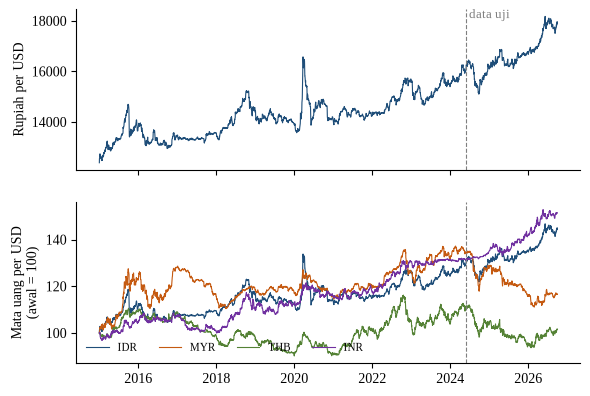

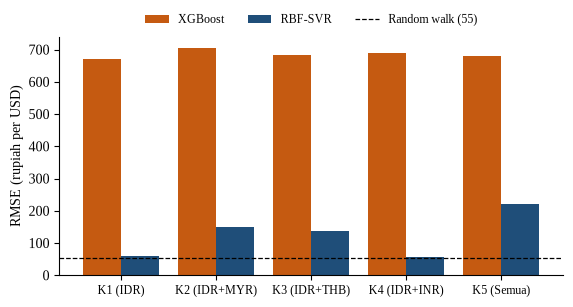

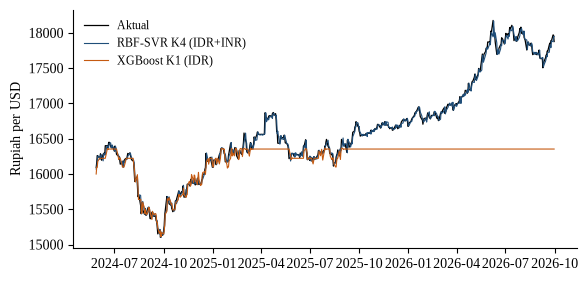

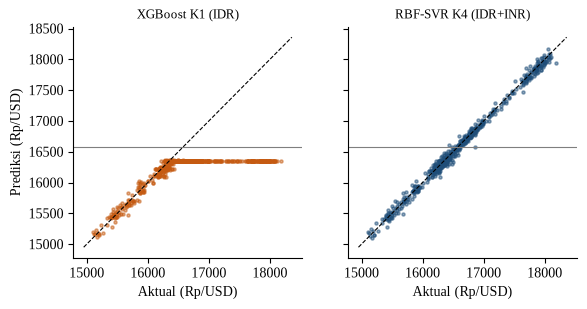

konfigurasi terbaik: {'XGBoost': 'K1 (IDR)', 'SVR': 'K4 (IDR+INR)'} | garis abu = batas atas rentang data latih


In [ ]:
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [
            "Times New Roman",
            "Liberation Serif",
            "Nimbus Roman",
            "DejaVu Serif",
        ],  # Liberation/Nimbus metrik-kompatibel dengan TNR
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.dpi": 220,
        "savefig.bbox": "tight",
    }
)
BIRU, ORANYE, ABU = "#1f4e79", "#c55a11", "#7f7f7f"
info = json.load(open("hasil/info.json"))
dfg = pd.read_csv("hasil/data_bersih.csv", parse_dates=[0], index_col=0)
pr = pd.read_csv("hasil/prediksi.csv", parse_dates=["tanggal"]).set_index("tanggal")
resg = pd.read_csv("hasil/hasil_utama.csv")
batas = pd.Timestamp(info["mulai_uji"])
m = resg[resg.algo != "Random walk"]
rw_rmse = resg.loc[resg.algo == "Random walk", "RMSE"].iloc[0]
best = {
    a: m[m.algo == a].sort_values("RMSE").konfigurasi.iloc[0]
    for a in ["XGBoost", "SVR"]
}

# Gambar 1: kurs target dan pergerakan relatif seluruh pasangan
fig, ax = plt.subplots(2, 1, figsize=(6.5, 4.6), sharex=True)
ax[0].plot(dfg[TARGET], color=BIRU, lw=0.8)
ax[0].axvline(batas, color=ABU, ls="--", lw=0.8)
ax[0].text(batas, ax[0].get_ylim()[1], " data uji", va="top", fontsize=9, color=ABU)
ax[0].set_ylabel("Rupiah per USD")
for c, col in zip(dfg.columns, [BIRU, ORANYE, "#548235", "#7030a0"]):
    ax[1].plot(dfg[c] / dfg[c].iloc[0] * 100, lw=0.8, color=col, label=c)
ax[1].axvline(batas, color=ABU, ls="--", lw=0.8)
ax[1].set_ylabel("Mata uang per USD\n(awal = 100)")
ax[1].legend(ncol=len(dfg.columns), frameon=False, fontsize=8, loc="lower left")
fig.savefig("hasil/gambar1_kurs.png")
plt.show()

# Gambar 2: RMSE per konfigurasi, dengan garis random walk
piv = (
    m.pivot(index="konfigurasi", columns="algo", values="RMSE")
    .loc[list(dict.fromkeys(m.konfigurasi)), ["XGBoost", "SVR"]]
    .rename(columns={"SVR": "RBF-SVR"})
)
fig, ax = plt.subplots(figsize=(6.5, 3.1))
piv.plot.bar(ax=ax, color=[ORANYE, BIRU], width=0.8, rot=0, legend=False)
garis = ax.axhline(rw_rmse, color="k", ls="--", lw=0.9)
ax.set_xlabel("")
ax.set_ylabel("RMSE (rupiah per USD)")
ax.tick_params(axis="x", labelsize=8.5)
ax.legend(
    [*ax.containers, garis],
    [*piv.columns, f"Random walk ({rw_rmse:,.0f})"],
    frameon=False,
    fontsize=8.5,
    ncol=3,
    loc="lower center",
    bbox_to_anchor=(0.5, 1),
)
fig.savefig("hasil/gambar2_rmse.png")
plt.show()

# Gambar 3: aktual vs prediksi konfigurasi terbaik tiap algoritma
fig, ax = plt.subplots(figsize=(6.5, 3.1))
ax.plot(pr.aktual, color="k", lw=0.9, label="Aktual")
ax.plot(pr[f"SVR|{best['SVR']}"], color=BIRU, lw=0.8, label=f"RBF-SVR {best['SVR']}")
ax.plot(
    pr[f"XGBoost|{best['XGBoost']}"],
    color=ORANYE,
    lw=0.8,
    label=f"XGBoost {best['XGBoost']}",
)
ax.set_ylabel("Rupiah per USD")
ax.legend(frameon=False, fontsize=8.5)
fig.savefig("hasil/gambar3_prediksi.png")
plt.show()

# Gambar 4: sebar aktual vs prediksi, memperlihatkan batas rentang data latih
fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.0), sharex=True, sharey=True)
lim = [pr.aktual.min() * 0.99, pr.aktual.max() * 1.01]
for a, nama, col, k in zip(
    ax, ["XGBoost", "RBF-SVR"], [ORANYE, BIRU], ["XGBoost", "SVR"]
):
    a.scatter(pr.aktual, pr[f"{k}|{best[k]}"], s=5, color=col, alpha=0.5)
    a.plot(lim, lim, "k--", lw=0.8)
    a.axhline(info["latih_maks"], color=ABU, lw=0.8)
    a.set_title(f"{nama} {best[k]}", fontsize=9.5)
    a.set_xlabel("Aktual (Rp/USD)")
ax[0].set_ylabel("Prediksi (Rp/USD)")
fig.savefig("hasil/gambar4_ekstrapolasi.png")
plt.show()

print("konfigurasi terbaik:", best, "| garis abu = batas atas rentang data latih")